In [61]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics.pairwise import cosine_similarity

In [5]:
# #### 2.2 · 🟢 Beginner · 10 min cap

# Data: `A = np.array([[3, 1], [0, 2]])`

# **Do**

# - Call `np.linalg.eig(A)` and unpack into `vals, vecs`. Print both and look at the shapes.
# - Loop over `i` in `range(len(vals))`. Take the column `v = vecs[:, i]` and `lam = vals[i]`. Test `np.allclose(A @ v, lam * v)` and print the result for each pair.
# - Print `vals.sum()` next to `np.trace(A)`. Print `np.prod(vals)` next to `np.linalg.det(A)`. Compare with `np.isclose`, because floats are never exactly equal.

In [6]:
A = np.array([[3, 1], 
              [0, 2]])

In [7]:
vals, vecs = np.linalg.eig(A)
print("Eigen Values: \n",vals)
print("Vals Shape: \n",vals.shape)
print("Eigen Vectors: \n",vecs)
print("Vecs Shape: \n",vecs.shape)

Eigen Values: 
 [3.+0.j 2.+0.j]
Vals Shape: 
 (2,)
Eigen Vectors: 
 [[ 1.        +0.j -0.70710678+0.j]
 [ 0.        +0.j  0.70710678+0.j]]
Vecs Shape: 
 (2, 2)


In [8]:
for i in range(len(vals)):
    v = vecs[:,i]
    lam = vals[i]

    print(np.allclose(A@v, lam*v))

True
True


In [9]:
print(vals.sum())
print(np.trace(A))
print(np.prod(vals))
print(np.linalg.det(A))

print(np.isclose(vals.sum(),np.trace(A)))
print(np.isclose(np.prod(vals),np.linalg.det(A)))

(5+0j)
5
(6+0j)
6.0
True
True


In [10]:
# #### 3.4 · 🟡 Above beginner · 15 min cap

# Data: `B = np.array([[2, 0], [0, 5]])` and `C = np.array([[1, 2], [2, 1]])`

# **Do**

# - [ ]  Run `np.linalg.eig` on `B`. Print the eigenvalues and eigenvectors. Write a comment on what the eigenvectors look like.
# - [ ]  Run `np.linalg.eigh` on `C`. Print both outputs.
# - [ ]  Check orthogonality: take the dot product of the two columns of `C`'s eigenvectors and test it against 0 with `np.isclose`.
# - [ ]  Rebuild `C` as `V @ np.diag(vals) @ V.T`. Test with `np.allclose(C, rebuilt)`.

# *Check: `B` has eigenvalues 2 and 5, and `C` has eigenvalues −1 and 3 (`eigh` sorts them from smallest to largest).*

In [11]:
B = np.array([[2, 0], [0, 5]])
C = np.array([[1, 2], [2, 1]])

In [14]:
val, vecs = np.linalg.eig(B)
print(val)
print("----")
print(vecs)

[2.+0.j 5.+0.j]
----
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]


In [17]:
velh, vecsh = np.linalg.eigh(B)
print(velh)
print(vecsh)

[2. 5.]
[[1. 0.]
 [0. 1.]]


In [25]:
valss, vecss = np.linalg.eigh(C)
print(val)
print(vecs)

[ 3.+0.j -1.+0.j]
[[ 0.70710678+0.j -0.70710678+0.j]
 [ 0.70710678+0.j  0.70710678+0.j]]


In [21]:
v1 = vecs[:, 0]
v2 = vecs[:, 1]

dot = np.dot(v1,v2)

print(np.isclose(dot,0))

True


In [26]:
V = vecss

c_rebuild = V @ np.diag(valss) @ V.T

print(np.allclose(c_rebuild,C))

True


In [27]:
# #### 1.6 · 🟠 Intermediate · 20 min cap

# Work in Jupyter. Put one markdown cell above each part, saying in one sentence what you do.

# Data: `M = np.array([[4, 2], [1, 3]])` and `N = np.array([[2, 1, 0], [1, 2, 1], [0, 1, 2]])`

# **Do**

# - [ ]  **Eigenpairs of `M`:** run `np.linalg.eig(M)`. For each column `v` and matching `lam`, test `np.allclose(M @ v, lam * v)`.
# - [ ]  **Rebuild `M`:** compute `V @ np.diag(vals) @ np.linalg.inv(V)` and compare with `M` using `np.allclose`.
# - [ ]  **Powers:** run `np.linalg.eig(M @ M)`. Sort its eigenvalues and `vals ** 2`. Compare with `np.allclose`.
# - [ ]  **Symmetric `N`:** run `np.linalg.eigh(N)`. Test `np.allclose(V.T @ V, np.eye(3))`.
# - [ ]  **SVD of `N`:** run `np.linalg.svd(N)`. Sort the singular values and the `eigh` eigenvalues and compare them. Add one comment saying why they match.

# *Check: `M` has eigenvalues 5 and 2, `M @ M` has 25 and 4, and the singular values of `N` equal its eigenvalues.*

In [29]:
M = np.array([[4, 2], 
              [1, 3]])

N = np.array([[2, 1, 0], 
              [1, 2, 1], 
              [0, 1, 2]])

In [32]:
vals, vects = np.linalg.eig(M)

In [ ]:
for i in range(len(vals)):
    v = vects[:, i]
    lam = vals[i]

    print(np.allclose(M@v, lam*v))

True
True


In [37]:
rebuild_M = vects @ np.diag(vals) @ np.linalg.inv(vects)
print(np.allclose(M, rebuild_M))

True


In [41]:
valm, vectm = np.linalg.eig(M @ M)
sortd_val = np.sort(valm)
vals_sq = np.sort(vals ** 2)

print(np.allclose(sortd_val,vals_sq))

True


In [42]:
# #### 2.6 · 🟢 Beginner · 10 min cap

# Data: `X = np.array([[1, 2], [2, 3], [3, 5], [4, 4]])`

# **Do**

# - [ ]  Create `PCA(n_components=1)` and fit-transform `X`.
# - [ ]  Print the transformed data and its shape.
# - [ ]  Print `model.explained_variance_` and `model.explained_variance_ratio_`.
# - [ ]  Print `model.components_` and identify the first principal direction.
# - [ ]  Optional check: calculate the covariance matrix with `np.cov(X, rowvar=False)` and its eigenvalues with `np.linalg.eigvalsh`.

In [44]:
X = np.array([[1, 2], 
              [2, 3], 
              [3, 5], 
              [4, 4]])
print(X.shape)

(4, 2)


In [47]:
pca = PCA(n_components=1)

In [51]:
Z = pca.fit_transform(X)
print(Z)
print(Z.shape)

[[-2.12132034]
 [-0.70710678]
 [ 1.41421356]
 [ 1.41421356]]
(4, 1)


In [53]:
print(pca.explained_variance_)
print(pca.explained_variance_ratio_)

[3.]
[0.9]


In [54]:
print(pca.components_)

[[0.70710678 0.70710678]]


In [55]:
print(pca.n_components_)
print(pca.n_features_in_)

1
2


In [57]:
covv = np.cov(X, rowvar = False)
print(covv)

[[1.66666667 1.33333333]
 [1.33333333 1.66666667]]


In [59]:
print(np.linalg.eigvalsh(covv))

[0.33333333 3.        ]


In [60]:
# #### 1.1 · 🟢 Beginner · 10 min cap

# Data: `f(x) = (x + 3)**2 + 1`, derivative `2*(x + 3)`. Start at x = 5, alpha = 0.2, 20 steps.

# **Do**

# - [ ]  Write `f` and its derivative as small functions.
# - [ ]  Write the loop. Keep a list `xs` that starts with the start value and gets every new `x`.
# - [ ]  Print `xs[i]` for every 5th step (use `range(0, 21, 5)`).
# - [ ]  Print the final `x` and `f(x)` at the final `x`.

# *Check: x ends close to −3, and f(x) ends close to 1.*

In [72]:
def f(x):
    return (x+3) ** 2 + 1

x_sym = sp.symbols('x')
f_expr = (x_sym+3)**2+1

df_expr = sp.diff(f_expr,x_sym)

def df(x):
    return 2*x+6



In [73]:
x = 5
alpha = 0.2
n = 20
xs = [5]

In [74]:
for i in range(n):
    derx = df(x)
    x_new = x - alpha * derx
    x = x_new
    xs.append(x_new)



In [75]:
for i in range(0,21,5):
    print(xs[i])

5
-2.37792
-2.9516270592
-2.996238520123392
-2.999707507324795


In [76]:
print(x)
print(f(x))

-2.999707507324795
1.000000085551965


In [77]:
# #### 3.8 · 🟢 Beginner · 10 min cap

# Data: `f(x) = (x - 2)**2`, derivative `2*(x - 2)`. Start at x = 6, alpha = 0.3, 10 steps.

# **Do**

# - [ ]  Run the loop and store every `x`.
# - [ ]  Plot `f` on `np.linspace(-1, 7, 200)`.
# - [ ]  Mark the visited points with `plt.scatter(xs, f(xs))`.
# - [ ]  Label the first and the last point with `plt.annotate`.

# *Check: the dots move toward x = 2, with big jumps at first and small jumps at the end.*

In [85]:
def f(x):
    return (x-2)**2

x_sym = sp.symbols('x')
f_expr = (x_sym -2) ** 2
df_expr = sp.diff(f_expr, x_sym)

def d(x):
    return 2*x - 4

In [86]:
x=6 
alpha = 0.3
n=10
xs=[x]

In [88]:
for i in range(n):
    derv_x = d(x)
    new_x = x - alpha * derv_x
    x = new_x
    xs.append(new_x)

for i in range(0,11,2):
    print(xs[i])
print(xs[10])

6
2.64
2.1024000000000003
2.016384
2.00262144
2.0004194304
2.0004194304


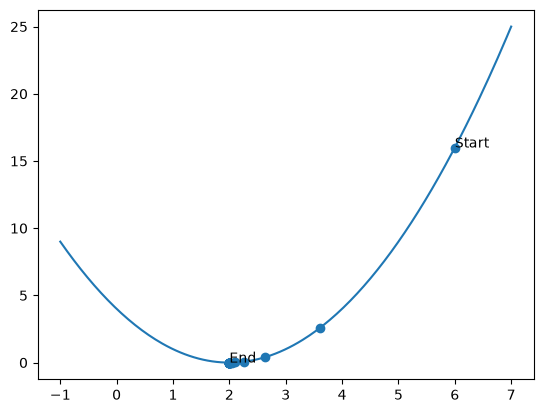

In [97]:
x_values = np.linspace(-1,7,200)
y_values = f(x_values)

plt.scatter(xs,f(np.array(xs)))

plt.annotate("Start", (xs[0], f(xs[0])))
plt.annotate("End", (xs[-1], f(xs[-1])))

plt.plot(x_values,y_values)
plt.show()

In [98]:
# Practice Task 3.9 — Gradient Descent
# Difficulty: Beginner
# Time limit: 15 minutes

# Given:
# \[
# f(x) = (x+4)^2 + 3
# \]
# Initial value: \(x = 8\)
# Learning rate: \(\alpha = 0.2\)
# Iterations: 12
# Requirements
# 1. Implement the complete optimization process.
# 2. Calculate the derivative.
# 3. Store every updated position.
# 4. Print the final position and function value.
# 5. Create a plot of the function over the interval \([-8, 10]\), using 200 points.
# 6. Display all visited positions on the plot.
# 7. Label the starting and ending positions.

In [101]:
def f(x):
    return (x+4)**2+3

x_sy = sp.symbols('x')
f_exp = (x_sy+4)**2+3
d_exp = sp.diff(f_exp, x_sy)

def d(x):
    return 2*x+8

In [ ]:
x=8
alpha = 0.2
n = 12 
xs=[x]

In [120]:
for i in range(n):
    dr_x = d(x)
    nw_x = x - alpha * dr_x
    x = nw_x
    xs.append(x)

print(x)
print(f(x))

-3.9999999999999996
3.0


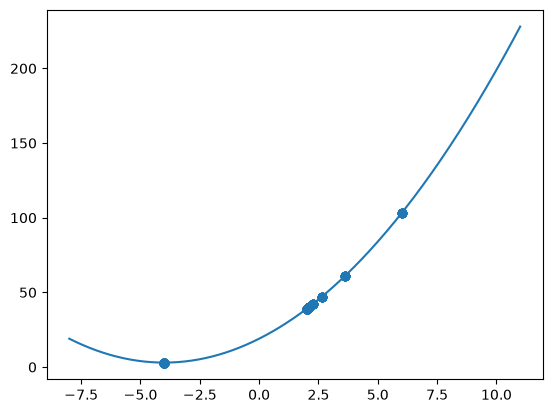

In [121]:
x_values = np.linspace(-8,11,200)

plt.plot(x_values,f(x_values))
plt.scatter(xs,f(np.array(xs)))


plt.show()

In [122]:
# #### 1.5 · 🟡 Above beginner · 15 min cap

# Data: `f(x) = (x - 1)**2 + 2`, derivative `2*(x - 1)`. Start at x = 5, 15 steps, alpha = 0.1, 0.6 and 1.05.

# **Do**

# - [ ]  Write one function that takes `alpha` and returns the list of `x` and the list of costs.
# - [ ]  Call it for the three alphas in a loop and keep the results in a dictionary.
# - [ ]  Chart 1: cost against iteration, three lines, legend.
# - [ ]  Chart 2: `x` against iteration, three lines, legend.
# - [ ]  Add one comment per curve saying what it does (slow, fast and oscillating, or growing).

In [125]:
def f(x):
    return (x-1)**2+2

x_symb = sp.symbols('x')
f_ex = (x_symb -1)**2+2
d_ex = sp.diff(f_ex,x_symb)

def d(x):
    return 2*x -2 

In [ ]:
def aplh(x):
    